## If a player fires random, non-repeating shots across a 10x10 grid, and all 5 fleets are randomly placed, non-overlapping and in uniform, what is the mean and standard deviation of the shots required to sink them?

We will conduct a Monte Carlo simulation using repeated random sampling of 10,000 trials. The study will simulate 10,000 Battleship games where we try to destroy all 5 fleets with randomly fired shots. Our random variable X represents the total number of shots required to sink all 5 ships in a single game. The fleet of ships occcupy 17 squares on a grid, so discrete integers 17-100 are theoretically possible.

In [1]:
import random
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def create_empty_board():
    board = []
    for r in range(10):
        row = []
        for c in range(10):
            row.append(0)
        board.append(row)
    return board

In [3]:
def can_place_horizontal(board, r, c, length):
    for i in range(length):
        if board[r][c + i] == 1:
            return False
    return True

In [4]:
def place_horizontal(board, r, c, length, target_cells):
    for i in range(length):
        board[r][c + i] = 1
        target_cells.append((r, c + i))

In [5]:
def can_place_vertical(board, r, c, length):
    for i in range(length):
        if board[r + i][c] == 1:
            return False
    return True

In [6]:
def place_vertical(board, r, c, length, target_cells):
    for i in range(length):
        board[r + i][c] = 1
        target_cells.append((r + i, c))

In [7]:
def place_ships():
    board = create_empty_board()
    ship_lengths = [5, 4, 3, 3, 2]
    target_cells = []
    
    for length in ship_lengths:
        placed = False
        while not placed:
            direction = random.randint(0, 1)
            
            if direction == 0:
                r = random.randint(0, 9)
                c = random.randint(0, 10 - length)
                if can_place_horizontal(board, r, c, length):
                    place_horizontal(board, r, c, length, target_cells)
                    placed = True
            else:
                r = random.randint(0, 10 - length)
                c = random.randint(0, 9)
                if can_place_vertical(board, r, c, length):
                    place_vertical(board, r, c, length, target_cells)
                    placed = True
                    
    return target_cells

In [8]:
def generate_shot_deck():
    all_shots = []
    for r in range(10):
        for c in range(10):
            all_shots.append((r, c))
    random.shuffle(all_shots)
    return all_shots

In [9]:
def simulate_one_game():
    targets = place_ships()
    total_targets = len(targets)
    all_shots = generate_shot_deck()
    
    hits = 0
    shots_fired = 0
    
    for shot in all_shots:
        shots_fired += 1
        if shot in targets:
            hits += 1
            if hits == total_targets:
                return shots_fired

In [10]:
NUM_TRIALS = 10000
results = []

for _ in range(NUM_TRIALS):
    results.append(simulate_one_game())

In [11]:
df = pd.DataFrame({'shots_to_sink': results})

In [12]:
sample_mean = df['shots_to_sink'].mean()
sample_std = df['shots_to_sink'].std()
min_shots = df['shots_to_sink'].min()
max_shots = df['shots_to_sink'].max()

In [15]:
print("=== STUDY RESULTS ===")
print(f"Sample Size (n):              {NUM_TRIALS:,} games")
print(f"Sample Mean (x̄):             {sample_mean:.2f} shots")
print(f"Sample Standard Dev (s):      {sample_std:.2f} shots")
print(f"Minimum Shots Recorded:       {min_shots} shots")
print(f"Maximum Shots Recorded:       {max_shots} shots")

=== STUDY RESULTS ===
Sample Size (n):              10,000 games
Sample Mean (x̄):             95.37 shots
Sample Standard Dev (s):      4.78 shots
Minimum Shots Recorded:       62 shots
Maximum Shots Recorded:       100 shots


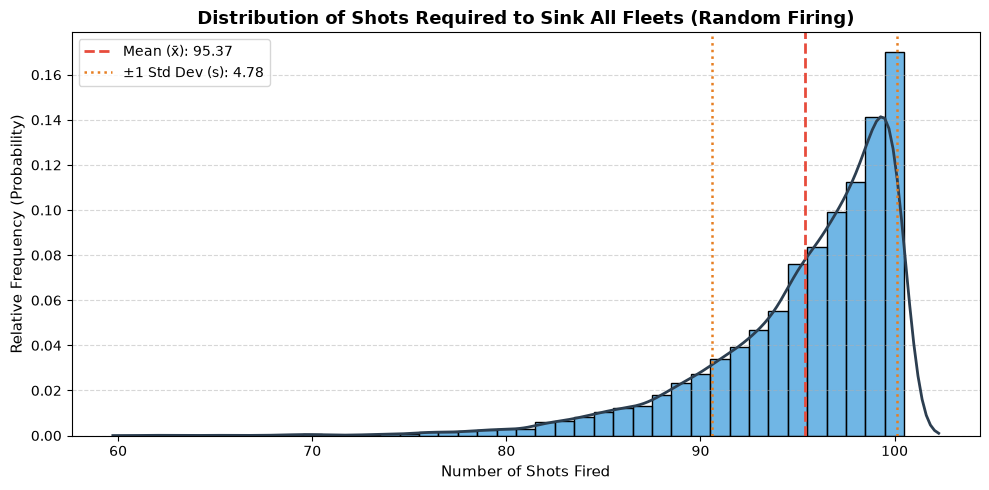

In [16]:
plt.figure(figsize=(10, 5))
sns.histplot(df['shots_to_sink'], discrete=True, stat="probability", color="#3498db", edgecolor="black", alpha=0.7)
sns.kdeplot(df['shots_to_sink'], color="#2c3e50", linewidth=2)

plt.axvline(sample_mean, color='#e74c3c', linestyle='--', linewidth=2, label=f'Mean (x̄): {sample_mean:.2f}')
plt.axvline(sample_mean - sample_std, color='#e67e22', linestyle=':', linewidth=1.8, label=f'±1 Std Dev (s): {sample_std:.2f}')
plt.axvline(sample_mean + sample_std, color='#e67e22', linestyle=':', linewidth=1.8)

plt.title('Distribution of Shots Required to Sink All Fleets (Random Firing)', fontsize=13, fontweight='bold')
plt.xlabel('Number of Shots Fired', fontsize=11)
plt.ylabel('Relative Frequency (Probability)', fontsize=11)
plt.legend(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### The left-skewness of the graph indicates that most games have a high shot-count.

### The simulation shows a strongly left-skewed distribution, where the mean number of shots required to win is  95.37 and the standard deviation is 4.78. The simulation can conclude that randomly guessing in Battleship is ineffective, since as it is inefficient and requires many shots.